# Model comparisons and story examples

Run cells from top to bottom using a Python environment with NumPy, Matplotlib and IPython installed. By default this notebook reads saved numerical results and story examples; it needs no checkpoints, PyTorch, GPU or Modal connection.

Plots save to `report/figures/`. The saved 18 story examples are read from `results/story-examples/samples.json`. Optional regeneration requires PyTorch, Transformers, the final checkpoints and saved tokenizer (see the settings below).

The prompts were chosen after numerical test evaluation, for qualitative illustration only—not as a new unbiased benchmark. Keep every output, including failures.


In [ ]:
from pathlib import Path
import json, statistics, hashlib, os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "results/full-test").exists():
    ROOT = ROOT.parent
assert (ROOT / "results/full-test").exists(), "Open this notebook from the repository root."
FIGURES = ROOT / "report/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SIZES = ["small", "medium", "large"]
COLORS = {"small": "#2878B5", "medium": "#D97527", "large": "#29845A"}

# Default: read the committed examples. Set True only to regenerate all examples.
REGENERATE_SAMPLES = False
# Checkpoints and data/tokens/tokenizer are expected beneath this root.
# For an external artifact directory, set the SMALL_LLM_ARTIFACT_ROOT environment
# variable before starting Jupyter. Relative paths are resolved against ROOT.
CHECKPOINT_ROOT = Path(os.environ.get("SMALL_LLM_ARTIFACT_ROOT", str(ROOT))).expanduser()
if not CHECKPOINT_ROOT.is_absolute():
    CHECKPOINT_ROOT = ROOT / CHECKPOINT_ROOT
def read_json(path):
    return json.loads(path.read_text())

runs = {}
for path in (ROOT / "results").rglob("summary.json"):
    s = read_json(path)
    if s.get("purpose") == "final" and s.get("status") == "completed":
        key = (s["model_size"], s["seed"])
        assert key not in runs, f"Duplicate completed run: {key}"
        metrics = [json.loads(line) for line in (path.parent / "metrics.jsonl").read_text().splitlines()]
        runs[key] = {"folder": path.parent, "settings": s, "metrics": metrics}
assert len(runs) == 6
print("Loaded six final runs. Figures:", FIGURES)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.svg", bbox_inches="tight")
    plt.show()


## 1. Learning curves

These are the **40-window monitoring validation losses**, not full-validation or test losses. Both panels show the same six runs. The second zooms into later training to make differences easier to see; neither averages mismatched time points.

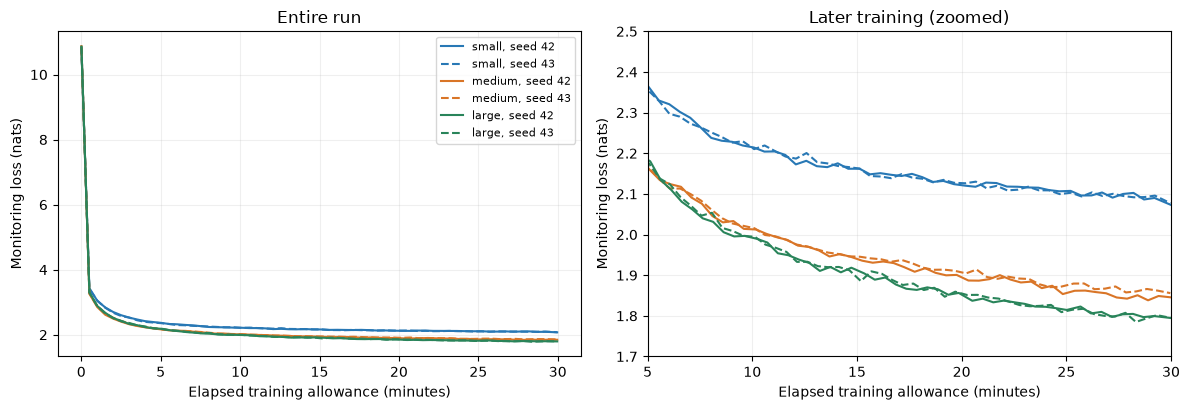

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for size in SIZES:
    for seed in [42, 43]:
        rows = [r for r in runs[(size, seed)]["metrics"] if "validation_loss" in r]
        for ax in axes:
            ax.plot([r["seconds"]/60 for r in rows],
                    [r["validation_loss"] for r in rows],
                    color=COLORS[size], linestyle="-" if seed == 42 else "--",
                    label=f"{size}, seed {seed}")
for ax in axes:
    ax.set(xlabel="Elapsed training allowance (minutes)", ylabel="Monitoring loss (nats)")
    ax.grid(alpha=.2)
axes[0].set_title("Entire run")
axes[1].set(xlim=(5, 30), ylim=(1.7, 2.5), title="Later training (zoomed)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "monitoring_curves")


## 2. Full validation and test performance

Dots show individual seeds, with mean ± **sample standard deviation across two seeds**. These are not confidence intervals. Lower is better. Perplexity is computed for each run before averaging.

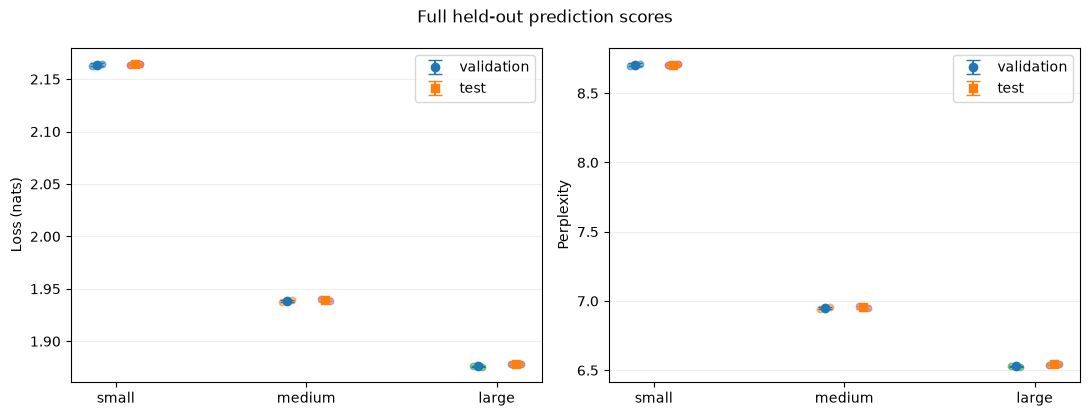

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for split, shift, marker in [("validation", -.10, "o"), ("test", .10, "s")]:
    for ax, metric, label in zip(axes, ["loss_nats", "perplexity"], ["Loss (nats)", "Perplexity"]):
        means, stds = [], []
        for i, size in enumerate(SIZES):
            values = [read_json(ROOT / f"results/full-{split}/{size}-s{seed}.json")[metric]
                      for seed in [42, 43]]
            means.append(statistics.mean(values))
            stds.append(statistics.stdev(values))
            ax.scatter([i+shift-.025, i+shift+.025], values, s=22, alpha=.5)
        ax.errorbar(np.arange(3)+shift, means, yerr=stds, fmt=marker,
                    capsize=5, label=split)
        ax.set(ylabel=label, xticks=range(3), xticklabels=SIZES)
        ax.grid(axis="y", alpha=.2)
for ax in axes:
    ax.legend()
fig.suptitle("Full held-out prediction scores")
fig.tight_layout()
save_figure(fig, "held_out_comparison")


## 3. Capacity versus training throughput

All runs used the same declared 30-minute allowance. Larger models processed fewer tokens. Hardware labels include both A10 and A10G; keep that limitation in the report.

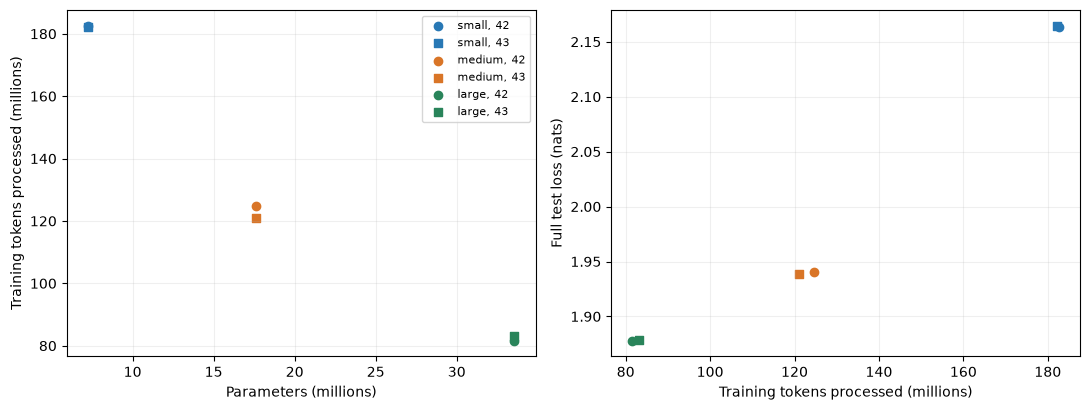

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for size in SIZES:
    for seed in [42, 43]:
        run = runs[(size, seed)]
        s = run["settings"]
        tokens = run["metrics"][-1]["tokens"] / 1e6
        params = s["parameters"] / 1e6
        test = read_json(ROOT / f"results/full-test/{size}-s{seed}.json")["loss_nats"]
        axes[0].scatter(params, tokens, color=COLORS[size], marker="o" if seed==42 else "s",
                        label=f"{size}, {seed}")
        axes[1].scatter(tokens, test, color=COLORS[size], marker="o" if seed==42 else "s")
axes[0].set(xlabel="Parameters (millions)", ylabel="Training tokens processed (millions)")
axes[1].set(xlabel="Training tokens processed (millions)", ylabel="Full test loss (nats)")
for ax in axes:
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "capacity_throughput")


## 4. Fixed-prompt story continuations

Use all three prompts for all six models. Generation settings are identical: temperature 0.8, top-k 50, at most 80 new tokens, and a fixed generation seed per prompt. The generation seed is separate from the model's training seed. Outputs may stop early at EOS or end mid-sentence at the token limit.

Read the samples for grammar, character consistency, cause/effect, relevance to the prompt and repetition. Do not regenerate until you get a preferred sample.

In [2]:
PROMPTS = [
    "Once upon a time, Mia found a small red key.",
    "Tom wanted to help his friend, but",
    "The little dog was afraid of the rain."
]
GENERATION = dict(max_new_tokens=80, do_sample=True, temperature=0.8, top_k=50)
print("Fixed prompts:", PROMPTS)


Fixed prompts: ['Once upon a time, Mia found a small red key.', 'Tom wanted to help his friend, but', 'The little dog was afraid of the rain.']


In [ ]:
EXAMPLES = ROOT / "results/story-examples"
SAMPLES_PATH = EXAMPLES / "samples.json"
if not REGENERATE_SAMPLES:
    saved = read_json(SAMPLES_PATH)
    assert saved["settings"] == GENERATION, "Saved generation settings differ."
    records = saved["samples"]
    expected_keys = {(size, seed, prompt) for size in SIZES
                     for seed in [42, 43] for prompt in PROMPTS}
    actual_keys = {(r["model_size"], r["training_seed"], r["prompt"]) for r in records}
    assert len(records) == 18 and actual_keys == expected_keys
    for record in records:
        expected = read_json(ROOT / (
            f"results/full-test/{record['model_size']}-s{record['training_seed']}.json"
        ))["checkpoint_sha256"]
        assert record["checkpoint_sha256"] == expected, "Sample checkpoint mismatch."
    print(f"Loaded {len(records)} saved continuations; no checkpoints required.")
else:
    import torch
    from transformers import GPT2Config, GPT2LMHeadModel, GPT2TokenizerFast
    torch.set_num_threads(4)
    tokenizer = GPT2TokenizerFast.from_pretrained(
        CHECKPOINT_ROOT / "data/tokens/tokenizer", local_files_only=True)
    EXAMPLES = ROOT / "results/story-examples"
    EXAMPLES.mkdir(parents=True, exist_ok=True)
    records = []
    for size in SIZES:
        for seed in [42, 43]:
            run = runs[(size, seed)]
            relative = run["folder"].relative_to(ROOT)
            checkpoint_path = CHECKPOINT_ROOT / relative / "checkpoint.pt"
            assert checkpoint_path.exists(), f"Missing checkpoint: {checkpoint_path}"
            expected = read_json(ROOT / f"results/full-test/{size}-s{seed}.json")["checkpoint_sha256"]
            assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == expected
            checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
            model = GPT2LMHeadModel(GPT2Config.from_pretrained(run["folder"])).eval()
            model.load_state_dict(checkpoint["model"], strict=True)
            for index, prompt in enumerate(PROMPTS):
                generation_seed = 2026 + index
                torch.manual_seed(generation_seed)
                inputs = tokenizer(prompt, return_tensors="pt")
                with torch.inference_mode():
                    output = model.generate(**inputs, **GENERATION,
                        pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
                continuation = tokenizer.decode(output[0, inputs["input_ids"].shape[1]:],
                                                skip_special_tokens=True)
                records.append(dict(model_size=size, training_seed=seed,
                    generation_seed=generation_seed, prompt=prompt, continuation=continuation,
                    generated_token_ids=output[0, inputs["input_ids"].shape[1]:].tolist(),
                    checkpoint_sha256=expected))
            del model, checkpoint
            print(f"Generated {size}, training seed {seed}")
    (EXAMPLES / "samples.json").write_text(json.dumps(
        {"settings": GENERATION, "torch_version": torch.__version__, "samples": records}, indent=2))
    print(f"Saved {len(records)} continuations.")


In [4]:
# Display every sample, grouped by prompt for direct model comparisons.
for prompt in PROMPTS:
    display(Markdown(f"### Prompt: {prompt}"))
    for record in records:
        if record["prompt"] == prompt:
            print(f"--- {record['model_size']} | training seed {record['training_seed']} ---")
            print(record["continuation"])
            print()


### Prompt: Once upon a time, Mia found a small red key.

--- small | training seed 42 ---
 She was so excited as she opened it and saw a small puzzle. She put it in her pocket and turned it on.

Mia wanted to try it. She pushed the puzzle with its arms and put it in her pocket. When she got home, she showed it to her mom. Her mom laughed and said it was a special puzzle.

Mia was so proud of her

--- small | training seed 43 ---
 The key was small and a shiny key that could unlock the lock. Mia put it in her pocket and turned it around.

As her mom was in the car, Mia saw a big bird in a tree. She wanted to fly it with her. She picked it up and put it on the ground. She was so happy and went back inside.

--- medium | training seed 42 ---
 The key was very tight and she wanted to unlock it, so she tried to open the key. But she couldn't find it.

Mia asked her mom, "What's under the box?" Her mom said, "I don't know. Let's keep trying and see." They searched and searched until they found the key under a rock. Mia was so happy to have her key

### Prompt: Tom wanted to help his friend, but

--- small | training seed 42 ---
 he couldn't help. He said to his friend, "I don't know, Tom. Let's go get the car!"

They walked up the stairs to the new toy car. They could not find the new toy. They both wanted to see the new car.

They went to the store, where they found the new car. They were very happy. They played with the

--- small | training seed 43 ---
 he couldn't help. So, Tim asked his mom, "Can we make another bird?" His mom said, "Yes, but they are too small." They looked around and saw a big tree with a nest in the sky. Tim was very happy and went to the tree. 

Afterwards, Tim and his little friend went home. Tim's mom gave him a big hug and

--- medium | training seed 42 ---
 he couldn't find his way back home. He decided to go to the vet to check him.

In the vet, he saw the dog again. He asked the dog if he could help him. The dog said yes and they both went to the vet.

The owner gave the dog a drink, and the dog licked his arm. The dog felt much better and they 

### Prompt: The little dog was afraid of the rain.

--- small | training seed 42 ---
 He wanted to be a good dog. He walked up to the stairs and started to run back to the park with his tail. He was happy to be out of the rain.

When he got to the park, the storm started to get dark and the little dog was too weak to go home. He barked and barked. The storm went down and the little dog was scared.

--- small | training seed 43 ---
 He wanted to be brave and stay here. 

But the little girl was scared and ran away.

The dog found a big box. It was a toy car with a picture of a kite. The kite was so happy and asked the girl if she wanted to play with it. The little girl wanted the kite back to the tree and keep it safe. 


--- medium | training seed 42 ---
 It barked and showed its teeth. Lily wanted to run away.

"Come on, dog!" Lily cried. "I dare you to get hurt!"

But the dog did not listen. It ran away with Lily and Ben. It barked and chased them. It grabbed them and ran away.

Lily and Ben heard the noise and ran to the house. They
